In [ ]:
# Import necessary libraries
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model
from tensorflow.keras.applications.inception_v3 import preprocess_input
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from google.colab import drive


In [ ]:
# Mount Google Drive
def mount_drive():
    drive.mount('/content/drive')


In [ ]:
# Load InceptionV3 for feature extraction
def load_feature_extractor():
    base_model = InceptionV3(weights="imagenet", include_top=False, input_shape=(128, 128, 3))
    return Model(inputs=base_model.input, outputs=base_model.output)


In [ ]:
# Function to preprocess and resize signature images
def preprocess_signature(image_path):
    image = cv2.imread(image_path)
    if image is None:
        print(f"Could not load image: {image_path}")
        return None
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)  # Convert to grayscale
    _, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY_INV)  # Thresholding
    resized = cv2.resize(thresh, (128, 128))  # Resize to model input size
    return cv2.merge([resized, resized, resized])  # Convert single channel to 3-channel


In [ ]:
# Function to extract features using InceptionV3
def extract_signature_features(signatures, model):
    preprocessed_signatures = preprocess_input(np.array(signatures))
    features = model.predict(preprocessed_signatures, batch_size=32)
    return features.reshape(features.shape[0], -1)


In [ ]:
# Function to create a feature database for signatures
def create_signature_features_database(data_path, model):
    feature_database = {}
    for person_name in os.listdir(data_path):
        person_path = os.path.join(data_path, person_name)
        if os.path.isdir(person_path):
            person_features = []
            for image_file in os.listdir(person_path):
                image_path = os.path.join(person_path, image_file)
                preprocessed_signature = preprocess_signature(image_path)
                if preprocessed_signature is not None:
                    features = extract_signature_features([preprocessed_signature], model)
                    if features is not None:
                        person_features.append(features)

            if person_features:
                feature_database[person_name] = np.vstack(person_features)

    return feature_database


In [ ]:
# Train a Random Forest Classifier
def train_rfc(features_db):
    X = []
    y = []

    # Prepare data for training
    for person_name, person_features in features_db.items():
        X.append(person_features)
        y.extend([person_name] * person_features.shape[0])

    X = np.vstack(X)
    y = np.array(y)

    # Split into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

    # Train a Random Forest Classifier
    clf = RandomForestClassifier(n_estimators=100, random_state=42)
    clf.fit(X_train, y_train)

    # Predict on training and testing sets
    y_pred_train = clf.predict(X_train)
    y_pred_test = clf.predict(X_test)

    # Calculate and print accuracy, precision, recall, and F1 score for training and testing
    print("Training Accuracy: ", accuracy_score(y_train, y_pred_train))
    print("Test Accuracy: ", accuracy_score(y_test, y_pred_test))

    print("Training Precision: ", precision_score(y_train, y_pred_train, average='weighted'))
    print("Test Precision: ", precision_score(y_test, y_pred_test, average='weighted'))

    print("Training Recall: ", recall_score(y_train, y_pred_train, average='weighted'))
    print("Test Recall: ", recall_score(y_test, y_pred_test, average='weighted'))

    print("Training F1 Score: ", f1_score(y_train, y_pred_train, average='weighted'))
    print("Test F1 Score: ", f1_score(y_test, y_pred_test, average='weighted'))

    return clf


In [ ]:
# Function to authenticate a signature
def authenticate_signature(new_signature_path, features_db, clf, model, threshold=0.7):
    preprocessed_signature = preprocess_signature(new_signature_path)
    if preprocessed_signature is None:
        print(f"Could not preprocess signature: {new_signature_path}")
        return

    # Extract features from the new signature
    new_features = extract_signature_features([preprocessed_signature], model)

    # Predict using the trained Random Forest Classifier
    predicted_person = clf.predict(new_features)
    predicted_prob = clf.predict_proba(new_features)

    # Check if the prediction probability is above the threshold
    best_similarity = np.max(predicted_prob)
    best_person = predicted_person[0]

    result_text = f"Signature not recognized. Best similarity: {best_similarity:.2f},"
    if best_similarity >= threshold:
        result_text = f"Authenticated as: {best_person}"

    # Load the image for plotting
    image = cv2.imread(new_signature_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert image to RGB for matplotlib

    # Plot the image with the authentication result
    plt.figure()
    plt.imshow(image_rgb, cmap='gray')
    plt.title(result_text)
    plt.axis('off')  # Hide axes
    plt.show()


Mounted at /content/drive
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 205ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 179ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/ste

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


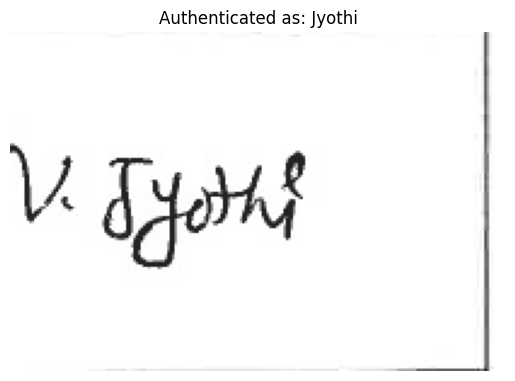

Authenticating signature: /content/drive/MyDrive/signs/jabeera/2-002_01.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step


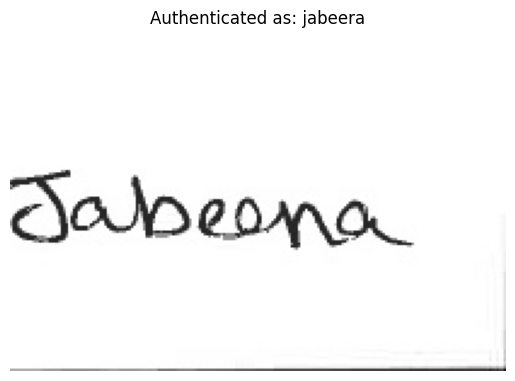

Authenticating signature: /content/drive/MyDrive/signs/reueui/1-002_02.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step


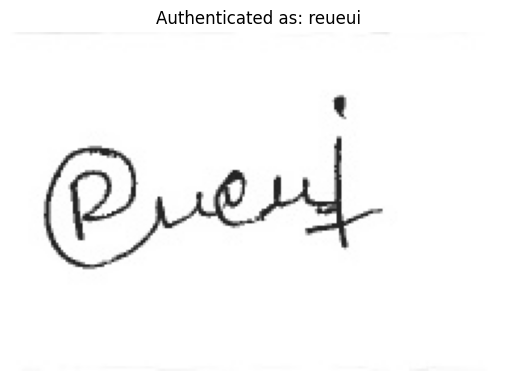

Authenticating signature: /content/drive/MyDrive/signs/Cristiano_Ronaldo_Signature.svg.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step


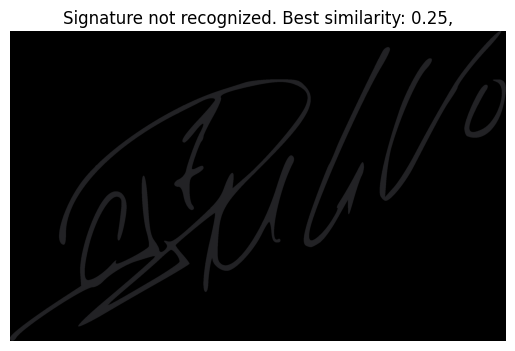

Authenticating signature: /content/drive/MyDrive/signs/reddi/102.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


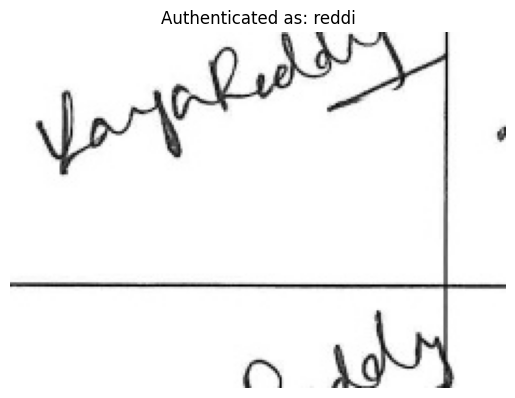

Authenticating signature: /content/drive/MyDrive/signs/Navya/1-003_010.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step


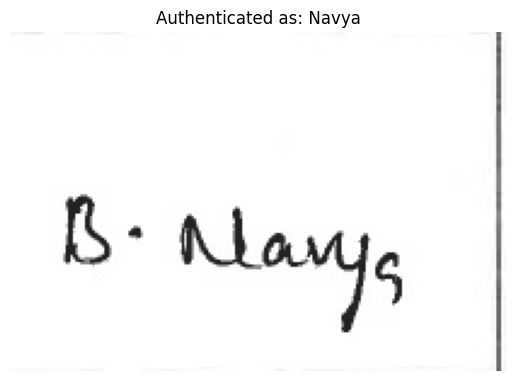

Authenticating signature: /content/drive/MyDrive/signs/saniya/2-004_01.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


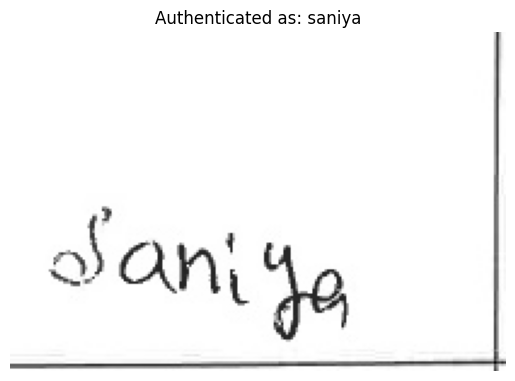

In [ ]:
# Main execution
if __name__ == "__main__":
    mount_drive()

    # Define paths
    data_path = "/content/drive/MyDrive/signs"
    test_signatures = [
        "/content/drive/MyDrive/signs/Jyothi/1-005_010.jpg",
        "/content/drive/MyDrive/signs/jabeera/2-002_01.jpg",
        "/content/drive/MyDrive/signs/reueui/1-002_02.jpg",
        "/content/drive/MyDrive/signs/Cristiano_Ronaldo_Signature.svg.png",
        "/content/drive/MyDrive/signs/reddi/102.jpg",
        "/content/drive/MyDrive/signs/Navya/1-003_010.jpg",
        "/content/drive/MyDrive/signs/saniya/2-004_01.jpg"
    ]

    # Load feature extractor
    model = load_feature_extractor()

    # Create feature database
    features_db = create_signature_features_database(data_path, model)

    # Train classifier
    clf = train_rfc(features_db)

    # Authenticate test signatures
    for new_signature_path in test_signatures:
        print(f"Authenticating signature: {new_signature_path}")
        authenticate_signature(new_signature_path, features_db, clf, model)
